## ZOMATO BUSINESS INTELLIGENCE AND DELIVERY TIME PREDICITION PLATFORM 

## Load all 12 CSVs

In [2]:
import pandas as pd, numpy as np
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
RAW = "data/raw/"
tables = ["cities","customers","restaurants","menu","delivery_partners","orders",
          "order_items","payments","customer_feedback","promotions","weather","traffic"]
d = {t: pd.read_csv(f"{RAW}{t}.csv") for t in tables}
print("Loaded", len(d), "tables")

Loaded 12 tables


## Overview

In [3]:
overview = pd.DataFrame({
    "rows": {t: len(df) for t, df in d.items()},
    "cols": {t: df.shape[1] for t, df in d.items()},
    "null_cells": {t: int(df.isna().sum().sum()) for t, df in d.items()},
    "duplicate_rows": {t: int(df.duplicated().sum()) for t, df in d.items()},
})
overview

,rows,cols,null_cells,duplicate_rows
cities,25,5,2,0
customers,12180,13,1319,180
restaurants,1200,13,34,0
menu,8997,8,132,0
delivery_partners,2000,10,34,0
orders,20705,15,13748,205
order_items,42378,6,435,0
payments,20493,6,183,0
customer_feedback,14200,7,1352,0
promotions,300,6,0,0


## each table (first rows + data types)
Change `t` to look at each table one by one. Note which columns are IDs, dates, numbers, text.

In [4]:
t = "orders"   # <- change this: customers, restaurants, menu, ...
display(d[t].head())
print(d[t].dtypes)

,OrderID,CustomerID,RestaurantID,DeliveryPartnerID,OrderDate,OrderTime,DeliveryTimeMinutes,FoodCost,DeliveryFee,Discount,CouponCode,GST,FinalAmount,OrderStatus,PaymentMethod
0,100001,7095,474,121,2023.06.17,11:51:00,43,206,40,103.0,ZOMKXZZW,10.30,153.30,Delivered,Cash on Delivery
1,100002,9498,828,1776,2023.07.01,10:18:00,18,425,20,127.5,ZOM72K4N,21.25,338.75,Food Not Delivered,Debit Card
2,100003,11040,105,27,2023-05-09,19:34:00,50,287,30,28.7,ZOMQJT3W,14.35,302.65,Cancelled,Net Banking
3,100004,2553,923,361,22-06-2024,00:26:00,29,60,25,0.0,NaN,3.00,88.00,Delivered,Credit Card
4,100005,8294,940,160,17/03/2024,12:27:00,25,582,49,145.5,ZOMCFY14,29.10,514.60,Delivered,UPI


OrderID                  int64
CustomerID               int64
RestaurantID             int64
DeliveryPartnerID        int64
OrderDate                  str
OrderTime                  str
DeliveryTimeMinutes      int64
FoodCost                 int64
DeliveryFee              int64
Discount               float64
CouponCode                 str
GST                    float64
FinalAmount            float64
OrderStatus                str
PaymentMethod              str
dtype: object


## missing values

In [5]:
for t, df in d.items():
    n = df.isna().sum(); n = n[n > 0]
    print(f"{t:20s}", dict(n) if len(n) else "no nulls")

cities               {'AverageIncome': np.int64(2)}
customers            {'Age': np.int64(170), 'Gender': np.int64(122), 'Phone': np.int64(144), 'Email': np.int64(332), 'State': np.int64(186), 'Membership': np.int64(120), 'PreferredCuisine': np.int64(245)}
restaurants          {'Cuisine': np.int64(12), 'Rating': np.int64(22)}
menu                 {'Calories': np.int64(132)}
delivery_partners    {'Rating': np.int64(34)}
orders               {'CouponCode': np.int64(13421), 'FinalAmount': np.int64(327)}
order_items          {'TotalPrice': np.int64(435)}
payments             {'TransactionID': np.int64(183)}
customer_feedback    {'CustomerRating': np.int64(294), 'Review': np.int64(1058)}
promotions           no nulls
weather              {'City': np.int64(91), 'Rainfall': np.int64(269)}
traffic              {'TrafficLevel': np.int64(147)}


## Primary keys

In [6]:
pk = {"cities":"CityID","customers":"CustomerID","restaurants":"RestaurantID","menu":"FoodItemID",
      "delivery_partners":"DeliveryPartnerID","orders":"OrderID","order_items":"OrderItemID",
      "payments":"PaymentID","customer_feedback":"FeedbackID","promotions":"PromotionID",
      "weather":"WeatherID","traffic":"TrafficID"}
rows = []
for t, k in pk.items():
    rows.append({"table": t, "pk": k, "null_pk": int(d[t][k].isna().sum()),
                 "duplicate_pk": int(d[t][k].duplicated().sum())})
pd.DataFrame(rows)

,table,pk,null_pk,duplicate_pk
0,cities,CityID,0,0
1,customers,CustomerID,0,180
2,restaurants,RestaurantID,0,0
3,menu,FoodItemID,0,0
4,delivery_partners,DeliveryPartnerID,0,0
5,orders,OrderID,0,205
6,order_items,OrderItemID,0,0
7,payments,PaymentID,0,0
8,customer_feedback,FeedbackID,0,0
9,promotions,PromotionID,0,0


**Note:** any table with `duplicate_pk > 0` cannot get a PRIMARY KEY constraint until it is de-duplicated 

## Foreign keys

In [7]:
fks = [("orders","CustomerID","customers","CustomerID"),
       ("orders","RestaurantID","restaurants","RestaurantID"),
       ("orders","DeliveryPartnerID","delivery_partners","DeliveryPartnerID"),
       ("orders","CouponCode","promotions","CouponCode"),
       ("menu","RestaurantID","restaurants","RestaurantID"),
       ("order_items","OrderID","orders","OrderID"),
       ("order_items","FoodItemID","menu","FoodItemID"),
       ("payments","OrderID","orders","OrderID"),
       ("customer_feedback","OrderID","orders","OrderID")]
out = []
for child, col, parent, pcol in fks:
    s = d[child][col].dropna()
    out.append({"relationship": f"{child}.{col} -> {parent}.{pcol}",
                "child_rows": len(s), "orphans": int((~s.isin(d[parent][pcol])).sum())})
pd.DataFrame(out)

,relationship,child_rows,orphans
0,orders.CustomerID -> customers.CustomerID,20705,12
1,orders.RestaurantID -> restaurants.RestaurantID,20705,13
2,orders.DeliveryPartnerID -> delivery_partners....,20705,0
3,orders.CouponCode -> promotions.CouponCode,7284,0
4,menu.RestaurantID -> restaurants.RestaurantID,8997,0
5,order_items.OrderID -> orders.OrderID,42378,0
6,order_items.FoodItemID -> menu.FoodItemID,42378,0
7,payments.OrderID -> orders.OrderID,20493,0
8,customer_feedback.OrderID -> orders.OrderID,14200,0


## City columns (customers/restaurants/delivery_partners/weather/traffic -> cities)


In [8]:
master = set(d["cities"]["City"])
for t in ["customers","restaurants","delivery_partners","weather","traffic"]:
    s = d[t]["City"].dropna()
    print(f"{t:18s} distinct raw spellings: {s.nunique():3d} | rows not matching master: {(~s.isin(master)).sum()}")
print()
print("Master list:", sorted(master))
print("\nExample bad spellings in customers:", d["customers"]["City"][~d["customers"]["City"].isin(master)].value_counts().head(10).to_dict())

customers          distinct raw spellings: 109 | rows not matching master: 1249
restaurants        distinct raw spellings:  91 | rows not matching master: 120
delivery_partners  distinct raw spellings: 100 | rows not matching master: 181
weather            distinct raw spellings:  25 | rows not matching master: 0
traffic            distinct raw spellings:  25 | rows not matching master: 0

Master list: ['Ahmedabad', 'Bengaluru', 'Bhopal', 'Bhubaneswar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Guwahati', 'Hyderabad', 'Indore', 'Jaipur', 'Kochi', 'Kolkata', 'Lucknow', 'Ludhiana', 'Mumbai', 'Nagpur', 'Nashik', 'Patna', 'Pune', 'Raipur', 'Surat', 'Vadodara', 'Visakhapatnam']

Example bad spellings in customers: {'KOLKATA': 36, 'chennai': 34, 'vadodara': 32, 'kolkata': 31, 'DELHI': 29, 'MUMBAI': 27, 'Baroda': 27, 'mumbai': 26, 'CHENNAI': 26, 'bengaluru': 26}


## Cardinality 
This decides how you draw the lines in the ER diagram.

In [9]:
print("order_items per order:\n", d["order_items"].groupby("OrderID").size().describe().round(2), "\n")
print("payments per order  :", d["payments"].groupby("OrderID").size().value_counts().to_dict())
print("feedback per order  :", d["customer_feedback"].groupby("OrderID").size().value_counts().to_dict())
print("orders with NO payment :", (~d["orders"]["OrderID"].isin(d["payments"]["OrderID"])).sum())
print("orders with NO feedback:", (~d["orders"]["OrderID"].isin(d["customer_feedback"]["OrderID"])).sum())

order_items per order:
 count    20487.00
mean         2.07
std          1.00
min          1.00
25%          1.00
50%          2.00
75%          3.00
max          7.00
dtype: float64 

payments per order  : {1: 19701, 2: 387, 3: 6}
feedback per order  : {1: 13970, 2: 115}
orders with NO payment : 406
orders with NO feedback: 6468


##  Save a findings log

In [10]:
import os; os.makedirs("reports", exist_ok=True)
overview.join(pd.DataFrame(rows).set_index("table")[["duplicate_pk"]]).to_csv("reports/day1_table_overview.csv")
pd.DataFrame(out).to_csv("reports/day1_fk_orphans.csv", index=False)
print("Saved to reports/")

Saved to reports/


In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, roc_auc_score, classification_report

In [12]:
RAW_DIR = 'data/raw/' if os.path.exists('data/raw/orders.csv') else ''
filename_map = {
    'cities': 'cities (1).csv' if os.path.exists(RAW_DIR + 'cities (1).csv') else 'cities.csv',
    'customers': 'customers (2).csv' if os.path.exists(RAW_DIR + 'customers (2).csv') else 'customers.csv',
    'restaurants': 'restaurants.csv',
    'menu': 'menu.csv',
    'delivery_partners': 'delivery_partners.csv',
    'orders': 'orders.csv',
    'order_items': 'order_items.csv',
    'payments': 'payments (1).csv' if os.path.exists(RAW_DIR + 'payments (1).csv') else 'payments.csv',
    'customer_feedback': 'customer_feedback (1).csv' if os.path.exists(RAW_DIR + 'customer_feedback (1).csv') else 'customer_feedback.csv',
    'promotions': 'promotions.csv',
    'weather': 'weather.csv',
    'traffic': 'traffic.csv'
}

d = {t: pd.read_csv(os.path.join(RAW_DIR, fn)).copy() for t, fn in filename_map.items()}

def clean_cities(df):
    df = df.drop_duplicates(subset=['CityID']).copy()
    df['City'] = df['City'].astype(str).str.strip().str.title()
    df['AverageIncome'] = df['AverageIncome'].fillna(df['AverageIncome'].median())
    return df

def clean_customers(df):
    df = df.drop_duplicates(subset=['CustomerID']).copy()
    df['Name'] = df['Name'].astype(str).str.strip().str.title()
    df['City'] = df['City'].astype(str).str.strip().str.title()
    df['State'] = df['State'].astype(str).str.strip().str.title()
    df['Membership'] = df['Membership'].fillna('Basic').astype(str).str.strip().str.title()
    df['Age'] = df['Age'].fillna(df['Age'].median())
    df['RegistrationDate'] = pd.to_datetime(df['RegistrationDate'], errors='coerce')
    return df

def clean_restaurants(df):
    df = df.drop_duplicates(subset=['RestaurantID']).copy()
    df['RestaurantName'] = df['RestaurantName'].astype(str).str.strip()
    df['Cuisine'] = df['Cuisine'].fillna('Mixed').astype(str).str.strip().str.title()
    df['City'] = df['City'].astype(str).str.strip().str.title()
    df['Rating'] = df['Rating'].fillna(df['Rating'].median())
    return df

def clean_menu(df):
    df = df.drop_duplicates(subset=['FoodItemID']).copy()
    df['FoodName'] = df['FoodName'].astype(str).str.strip()
    df['Calories'] = df['Calories'].fillna(df['Calories'].median())
    return df

def clean_delivery_partners(df):
    df = df.drop_duplicates(subset=['DeliveryPartnerID']).copy()
    df['Name'] = df['Name'].astype(str).str.strip().str.title()
    df['City'] = df['City'].astype(str).str.strip().str.title()
    df['Rating'] = df['Rating'].fillna(df['Rating'].median())
    return df

def clean_orders(df):
    df = df.drop_duplicates(subset=['OrderID']).copy()
    df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce')
    for col in ['FoodCost', 'DeliveryFee', 'DeliveryTimeMinutes', 'FinalAmount']:
        if col in df.columns:
            df[col] = df[col].apply(lambda x: np.nan if x <= 0 else x)
            df[col] = df[col].fillna(df[col].median())
    df['OrderStatus'] = df['OrderStatus'].astype(str).str.strip().str.title()
    df['PaymentMethod'] = df['PaymentMethod'].astype(str).str.strip()
    return df

def clean_order_items(df):
    df = df.drop_duplicates(subset=['OrderItemID']).copy()
    missing_total = df['TotalPrice'].isna()
    df.loc[missing_total, 'TotalPrice'] = df.loc[missing_total, 'Quantity'] * df.loc[missing_total, 'UnitPrice']
    return df

def clean_payments(df):
    df = df.drop_duplicates(subset=['PaymentID']).copy()
    df['PaymentMethod'] = df['PaymentMethod'].astype(str).str.strip()
    df['PaymentStatus'] = df['PaymentStatus'].astype(str).str.strip().str.title()
    df['PaymentDate'] = pd.to_datetime(df['PaymentDate'], errors='coerce')
    return df

def clean_customer_feedback(df):
    df = df.drop_duplicates(subset=['FeedbackID']).copy()
    df['CustomerRating'] = df['CustomerRating'].fillna(df['CustomerRating'].median())
    df['Sentiment'] = df['Sentiment'].fillna('Neutral').astype(str).str.strip().str.title()
    return df

def clean_promotions(df):
    df = df.drop_duplicates(subset=['PromotionID']).copy()
    df['CouponCode'] = df['CouponCode'].astype(str).str.strip()
    df['StartDate'] = pd.to_datetime(df['StartDate'], errors='coerce')
    df['EndDate'] = pd.to_datetime(df['EndDate'], errors='coerce')
    return df

def clean_weather(df):
    df = df.drop_duplicates(subset=['WeatherID']).copy()
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df['Rainfall'] = df['Rainfall'].fillna(0.0)
    df['City'] = df['City'].astype(str).str.strip().str.title()
    return df

def clean_traffic(df):
    df = df.drop_duplicates(subset=['TrafficID']).copy()
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df['TrafficLevel'] = df['TrafficLevel'].fillna('Moderate').astype(str).str.strip().str.title()
    df['City'] = df['City'].astype(str).str.strip().str.title()
    return df

cleaned_d = {
    'cities': clean_cities(d['cities']),
    'customers': clean_customers(d['customers']),
    'restaurants': clean_restaurants(d['restaurants']),
    'menu': clean_menu(d['menu']),
    'delivery_partners': clean_delivery_partners(d['delivery_partners']),
    'orders': clean_orders(d['orders']),
    'order_items': clean_order_items(d['order_items']),
    'payments': clean_payments(d['payments']),
    'customer_feedback': clean_customer_feedback(d['customer_feedback']),
    'promotions': clean_promotions(d['promotions']),
    'weather': clean_weather(d['weather']),
    'traffic': clean_traffic(d['traffic'])
}

In [13]:
def standardize_city_names(df, city_col='City'):
    if city_col in df.columns:
        df[city_col] = df[city_col].astype(str).str.strip().str.title()
        replacements = {'Bangalore': 'Bengaluru', 'Baroda': 'Vadodara'}
        df[city_col] = df[city_col].replace(replacements)
    return df

def clean_phone_pincode(df):
    if 'Phone' in df.columns:
        df['Phone'] = df['Phone'].astype(str).str.replace(r'\D', '', regex=True)
        df.loc[df['Phone'].str.len() < 10, 'Phone'] = np.nan
    if 'Pincode' in df.columns:
        df['Pincode'] = df['Pincode'].astype(str).str.replace(r'\D', '', regex=True)
    return df

for name in ['customers', 'restaurants', 'delivery_partners', 'weather', 'traffic']:
    cleaned_d[name] = standardize_city_names(cleaned_d[name])

cleaned_d['customers'] = clean_phone_pincode(cleaned_d['customers'])

In [14]:
abt = cleaned_d['orders'].merge(
    cleaned_d['customers'][['CustomerID', 'RegistrationDate', 'Membership', 'City']],
    on='CustomerID', how='left', suffixes=('', '_cust')
)
abt = abt.merge(
    cleaned_d['restaurants'][['RestaurantID', 'Cuisine', 'Rating', 'AverageCost']],
    on='RestaurantID', how='left'
)

In [15]:

# Merge Delivery Partners to bring in AverageDeliveryTime for DeliveryEfficiency
abt = abt.merge(
    cleaned_d['delivery_partners'][['DeliveryPartnerID', 'AverageDeliveryTime']],
    on='DeliveryPartnerID', how='left', suffixes=('', '_partner')
)

# ---------------------------------------------------------
abt['OrderHour'] = pd.to_datetime(abt['OrderTime'], format='%H:%M:%S', errors='coerce').dt.hour
abt['PeakHour'] = abt['OrderHour'].apply(lambda h: 1 if (12 <= h <= 14) or (19 <= h <= 22) else 0)
abt['DayOfWeek'] = abt['OrderDate'].dt.dayofweek
abt['WeekendOrder'] = abt['DayOfWeek'].apply(lambda d: 1 if d >= 5 else 0)

abt['CustomerTenure'] = (abt['OrderDate'] - abt['RegistrationDate']).dt.days
abt['AverageBasketValue'] = abt.groupby('CustomerID')['FinalAmount'].transform('mean')

# Compute DeliveryEfficiency safely now that AverageDeliveryTime is present in abt
abt['DeliveryEfficiency'] = abt['DeliveryTimeMinutes'] / (abt['AverageDeliveryTime'] + 1)

# Merge Weather & Traffic environmental factors
weather_df = cleaned_d['weather'].copy()
weather_df['DateOnly'] = weather_df['Date'].dt.date

traffic_df = cleaned_d['traffic'].copy()
traffic_df['DateOnly'] = traffic_df['Date'].dt.date

abt['DateOnly'] = abt['OrderDate'].dt.date

abt = abt.merge(
    weather_df[['City', 'DateOnly', 'Rainfall', 'Temperature']].drop_duplicates(subset=['City', 'DateOnly']),
    on=['City', 'DateOnly'], how='left'
)
abt['RainImpact'] = abt['Rainfall'].apply(lambda r: 2 if r > 20 else (1 if r > 5 else 0))

abt = abt.merge(
    traffic_df[['City', 'DateOnly', 'TrafficLevel', 'AverageSpeed']].drop_duplicates(subset=['City', 'DateOnly']),
    on=['City', 'DateOnly'], how='left'
)
traffic_mapping = {'Low': 1, 'Moderate': 2, 'High': 3, 'Severe': 4}
abt['TrafficScore'] = abt['TrafficLevel'].map(traffic_mapping).fillna(2)

display(abt[['OrderID', 'PeakHour', 'WeekendOrder', 'CustomerTenure', 'AverageBasketValue', 'DeliveryEfficiency']].head(3))

,OrderID,PeakHour,WeekendOrder,CustomerTenure,AverageBasketValue,DeliveryEfficiency
0,100001,0,1,NaN,354.950000,0.890269
1,100002,0,1,NaN,477.466667,0.369610
2,100003,1,0,NaN,302.650000,1.633987


In [16]:
validation_report = pd.DataFrame({
    'Validation Metric': [
        'Total Cleaned Orders',
        'Duplicate OrderIDs',
        'Missing Customer IDs',
        'Missing Restaurant IDs',
        'ABT Total Columns'
    ],
    'Result': [
        len(abt),
        int(abt.duplicated(subset=['OrderID']).sum()),
        int(abt['CustomerID'].isna().sum()),
        int(abt['RestaurantID'].isna().sum()),
        abt.shape[1]
    ]
})

print(validation_report)

        Validation Metric  Result
0    Total Cleaned Orders   20500
1      Duplicate OrderIDs       0
2    Missing Customer IDs       0
3  Missing Restaurant IDs       0
4       ABT Total Columns      36


In [17]:
# 1. Delivery Time Regression
reg_features = ['PeakHour', 'WeekendOrder', 'FoodCost', 'DeliveryFee', 'TrafficScore', 'RainImpact', 'CustomerTenure', 'AverageCost', 'Rating']
X_reg = abt[reg_features].fillna(abt.median(numeric_only=True))
y_reg = abt['DeliveryTimeMinutes'].fillna(abt['DeliveryTimeMinutes'].median())

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_tr_r, y_tr_r)
preds_r = rf_reg.predict(X_te_r)

print('\n--- MODEL 1: DELIVERY TIME REGRESSION (RANDOM FOREST) ---')
print(f'MAE  : {mean_absolute_error(y_te_r, preds_r):.2f} minutes')
print(f'RMSE : {np.sqrt(mean_squared_error(y_te_r, preds_r)):.2f} minutes')
print(f'R2   : {r2_score(y_te_r, preds_r):.4f}')


--- MODEL 1: DELIVERY TIME REGRESSION (RANDOM FOREST) ---
MAE  : 13.69 minutes
RMSE : 26.78 minutes
R2   : -0.1058


In [18]:
# 2. Customer Churn Classification
max_date = abt['OrderDate'].max()
cust_last = abt.groupby('CustomerID')['OrderDate'].max().reset_index()
cust_last['DaysSinceLast'] = (max_date - cust_last['OrderDate']).dt.days
cust_last['Churn60'] = cust_last['DaysSinceLast'].apply(lambda d: 1 if d > 60 else 0)

abt_c = abt.merge(cust_last[['CustomerID', 'Churn60']], on='CustomerID', how='left')
clf_features = ['CustomerTenure', 'PeakHour', 'WeekendOrder', 'AverageBasketValue']
X_c = abt_c[clf_features].fillna(0)
y_c = abt_c['Churn60'].fillna(0)

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_c, y_c, test_size=0.2, random_state=42, stratify=y_c)
rf_clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_clf.fit(X_tr_c, y_tr_c)
preds_c = rf_clf.predict(X_te_c)
probs_c = rf_clf.predict_proba(X_te_c)[:, 1]

print('\n--- MODEL 2: CUSTOMER CHURN CLASSIFICATION (RANDOM FOREST) ---')
print(f'F1-Score: {f1_score(y_te_c, preds_c):.4f}')
print(f'ROC-AUC : {roc_auc_score(y_te_c, probs_c):.4f}')
print('\nClassification Report:')
print(classification_report(y_te_c, preds_c))


--- MODEL 2: CUSTOMER CHURN CLASSIFICATION (RANDOM FOREST) ---
F1-Score: 0.7045
ROC-AUC : 0.7807

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.78      0.80      2508
           1       0.68      0.74      0.70      1592

    accuracy                           0.76      4100
   macro avg       0.75      0.76      0.75      4100
weighted avg       0.77      0.76      0.76      4100



# `QUESTIONS`

>Which restaurants and cuisines are top revenue generators, and how has that changed over time?


--- TOP 10 REVENUE-GENERATING RESTAURANTS ---


,RestaurantID,RestaurantName,Cuisine,TotalRevenue,OrderCount,AvgOrderValue
1126,1127,Spicy Diner,Pizza,9130.20,19,480.536842
872,873,Grand Bites,Desserts,8922.25,22,405.556818
295,296,Golden Treats,Pizza,8728.75,18,484.930556
534,535,Curry Cafe,South Indian,8208.25,19,432.013158
379,380,Spicy Corner,Biryani,7780.95,19,409.523684
472,473,Blue Bites,Seafood,7649.25,16,478.078125
353,354,Spicy Grill,Italian,7559.60,18,419.977778
303,304,Golden Grill,Sushi,7478.15,19,393.586842
28,29,Curry Grill,Fast Food,7402.10,18,411.227778
489,490,Green Corner,Sushi,7335.60,19,386.084211



--- REVENUE BY CUISINE ---


,Cuisine,TotalRevenue,OrderCount,RevenueSharePct
16,South Indian,312469.60,784,6.978150
7,Fast Food,280643.90,715,6.267410
8,Healthy Food,267465.75,694,5.973112
14,Pizza,247817.90,604,5.534332
6,Desserts,247533.95,632,5.527990
18,Sushi,243720.10,620,5.442818
17,Street Food,243682.90,623,5.441988
5,Continental,238018.80,611,5.315496
1,Bbq,236260.85,606,5.276237
15,Seafood,233387.75,597,5.212074


C:\Users\dell\AppData\Local\Temp\ipykernel_14852\3615177529.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


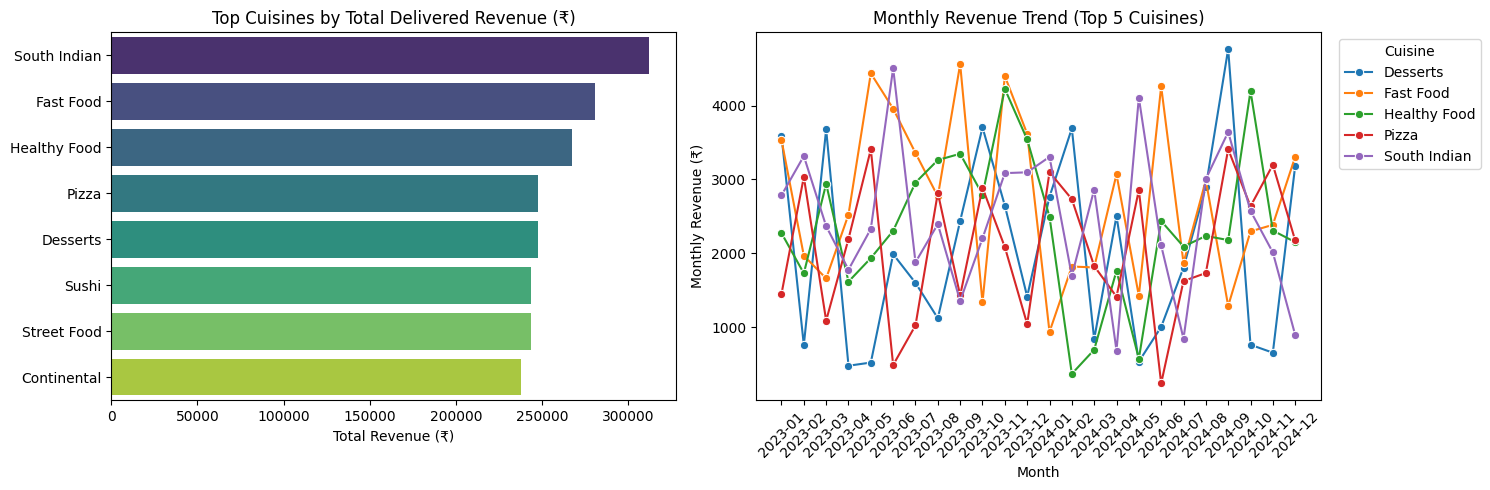

In [20]:
# Filter for valid, completed revenue only
rev_df = abt[abt['OrderStatus'] == 'Delivered'].copy()
rev_df['YearMonth'] = rev_df['OrderDate'].dt.to_period('M').astype(str)

# Bring in RestaurantName from cleaned_d['restaurants'] if not already in abt
if 'RestaurantName' not in rev_df.columns:
    rev_df = rev_df.merge(
        cleaned_d['restaurants'][['RestaurantID', 'RestaurantName']], 
        on='RestaurantID', 
        how='left'
    )

# Top 10 Revenue-Generating Restaurants
top_restaurants = (
    rev_df.groupby(['RestaurantID', 'RestaurantName', 'Cuisine'], as_index=False)
    .agg(
        TotalRevenue=('FinalAmount', 'sum'),
        OrderCount=('OrderID', 'count'),
        AvgOrderValue=('FinalAmount', 'mean')
    )
    .sort_values('TotalRevenue', ascending=False)
    .head(10)
)
print("--- TOP 10 REVENUE-GENERATING RESTAURANTS ---")
display(top_restaurants)

# Top Revenue-Generating Cuisines
top_cuisines = (
    rev_df.groupby('Cuisine', as_index=False)
    .agg(
        TotalRevenue=('FinalAmount', 'sum'),
        OrderCount=('OrderID', 'count'),
        RevenueSharePct=('FinalAmount', lambda x: (x.sum() / rev_df['FinalAmount'].sum()) * 100)
    )
    .sort_values('TotalRevenue', ascending=False)
)
print("\n--- REVENUE BY CUISINE ---")
display(top_cuisines)

# Visualize Cuisine Revenue Trends Over Time (Top 5 Cuisines)
top_5_cuisine_names = top_cuisines['Cuisine'].head(5).tolist()
trend_df = (
    rev_df[rev_df['Cuisine'].isin(top_5_cuisine_names)]
    .groupby(['YearMonth', 'Cuisine'], as_index=False)['FinalAmount']
    .sum()
    .sort_values('YearMonth')
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Bar Chart: Top Cuisines Total Revenue
sns.barplot(
    data=top_cuisines.head(8), 
    x='TotalRevenue', 
    y='Cuisine', 
    palette='viridis', 
    ax=axes[0]
)
axes[0].set_title('Top Cuisines by Total Delivered Revenue (₹)')
axes[0].set_xlabel('Total Revenue (₹)')
axes[0].set_ylabel('')

# Line Chart: Monthly Revenue Trajectory for Top 5 Cuisines
sns.lineplot(
    data=trend_df, 
    x='YearMonth', 
    y='FinalAmount', 
    hue='Cuisine', 
    marker='o', 
    ax=axes[1]
)
axes[1].set_title('Monthly Revenue Trend (Top 5 Cuisines)')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Monthly Revenue (₹)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Cuisine', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

>What are the peak ordering hours and how do weekday and weekend patterns differ?

--- WEEKDAY VS. WEEKEND SUMMARY ---


,DayType,TotalOrders,OrderSharePct,AvgBasketValue,PeakHourSharePct
0,Weekday (Mon–Fri),19347,94.37561,391.291552,46.834134
1,Weekend (Sat–Sun),1153,5.62439,400.240763,47.701648



--- TOP 5 PEAK ORDERING HOURS ---


,OrderHour,OrderCount,SharePct,AvgOrderValue
19,19,1801,8.785366,394.433287
12,12,1750,8.536585,392.126886
13,13,1664,8.117073,393.143660
20,20,1633,7.965854,394.365493
18,18,1476,7.200000,382.929370


C:\Users\dell\AppData\Local\Temp\ipykernel_14852\3853315194.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


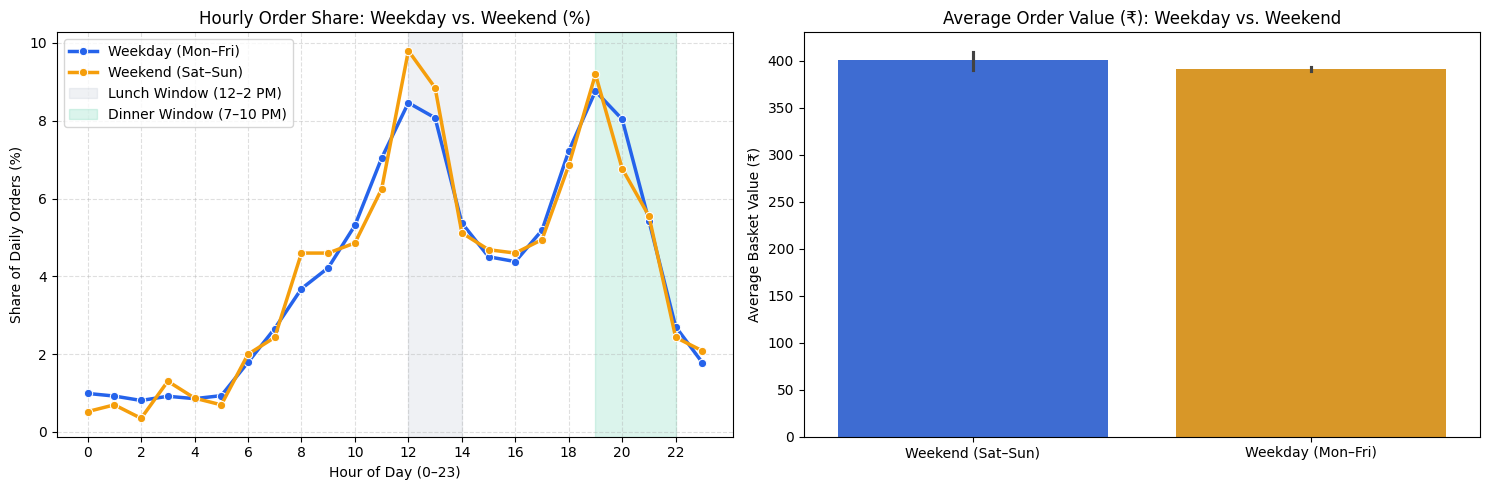

In [21]:
# Ensure DayOfWeek and IsWeekend are cleanly derived
hourly_df = abt.copy()
hourly_df['DayType'] = hourly_df['WeekendOrder'].map({1: 'Weekend (Sat–Sun)', 0: 'Weekday (Mon–Fri)'})

# Summary Table: Weekday vs. Weekend Comparison
daytype_summary = (
    hourly_df.groupby('DayType', as_index=False)
    .agg(
        TotalOrders=('OrderID', 'count'),
        OrderSharePct=('OrderID', lambda x: (len(x) / len(hourly_df)) * 100),
        AvgBasketValue=('FinalAmount', 'mean'),
        PeakHourSharePct=('PeakHour', lambda x: x.mean() * 100)
    )
)
print("--- WEEKDAY VS. WEEKEND SUMMARY ---")
display(daytype_summary)

# Top 5 Peak Ordering Hours Overall
top_hours = (
    hourly_df.groupby('OrderHour', as_index=False)
    .agg(
        OrderCount=('OrderID', 'count'),
        SharePct=('OrderID', lambda x: (len(x) / len(hourly_df)) * 100),
        AvgOrderValue=('FinalAmount', 'mean')
    )
    .sort_values('OrderCount', ascending=False)
)
print("\n--- TOP 5 PEAK ORDERING HOURS ---")
display(top_hours.head(5))

# Hourly Distribution: Normalized Share (%) for Weekday vs. Weekend
hourly_dist = (
    hourly_df.groupby(['DayType', 'OrderHour'], as_index=False)['OrderID']
    .count()
    .rename(columns={'OrderID': 'OrderCount'})
)
hourly_dist['PctWithinDayType'] = (
    hourly_dist['OrderCount'] / hourly_dist.groupby('DayType')['OrderCount'].transform('sum')
) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Chart 1: Hourly Order Curve (Weekday vs. Weekend)
sns.lineplot(
    data=hourly_dist,
    x='OrderHour',
    y='PctWithinDayType',
    hue='DayType',
    marker='o',
    linewidth=2.5,
    palette=['#2563EB', '#F59E0B'],
    ax=axes[0]
)
axes[0].axvspan(12, 14, color='#94A3B8', alpha=0.15, label='Lunch Window (12–2 PM)')
axes[0].axvspan(19, 22, color='#10B981', alpha=0.15, label='Dinner Window (7–10 PM)')
axes[0].set_title('Hourly Order Share: Weekday vs. Weekend (%)')
axes[0].set_xlabel('Hour of Day (0–23)')
axes[0].set_ylabel('Share of Daily Orders (%)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend()

# Chart 2: Average Basket Value by Hour (Weekday vs. Weekend)
sns.barplot(
    data=hourly_df,
    x='DayType',
    y='FinalAmount',
    palette=['#2563EB', '#F59E0B'],
    ax=axes[1]
)
axes[1].set_title('Average Order Value (₹): Weekday vs. Weekend')
axes[1].set_xlabel('')
axes[1].set_ylabel('Average Basket Value (₹)')

plt.tight_layout()
plt.show()

>What is the distribution of delivery times, and how does it vary by city, traffic level, and weather condition?

Using weather column: 'RainImpact'

--- OVERALL DELIVERY TIME DISTRIBUTION (MINUTES) ---


,count,mean,std,min,25%,50%,75%,90%,95%,max
DeliveryTimeMinutes,9486.0,35.425047,24.636521,8.0,27.0,34.0,40.0,47.0,50.0,399.0



--- DELIVERY TIME BY CITY ---


,City,OrderCount,MeanMins,MedianMins,P90Mins
4,Chandigarh,408,36.078431,35.0,47.0
12,Kochi,386,35.088083,35.0,48.0
13,Kolkata,348,36.091954,34.5,48.0
7,Delhi,374,34.406417,34.0,46.0
1,Bengaluru,357,34.000000,34.0,45.0
8,Guwahati,354,33.954802,34.0,44.0
14,Lucknow,377,35.801061,34.0,47.0
6,Coimbatore,400,36.112500,34.0,46.0
5,Chennai,357,35.092437,34.0,46.0
23,Vadodara,376,36.521277,34.0,47.0



--- DELIVERY TIME BY TRAFFIC & WEATHER ---


,TrafficLevel,RainImpact,OrderCount,MedianMins,P90Mins
9,Severe,0,399,35.0,48.0
11,Severe,2,395,35.0,47.0
0,High,0,446,34.0,46.0
1,High,1,737,34.0,47.0
3,Low,0,1562,34.0,46.0
2,High,2,813,34.0,47.0
4,Low,1,727,34.0,47.0
6,Moderate,0,2225,34.0,47.0
7,Moderate,1,672,33.5,46.0
8,Moderate,2,1090,33.0,45.0


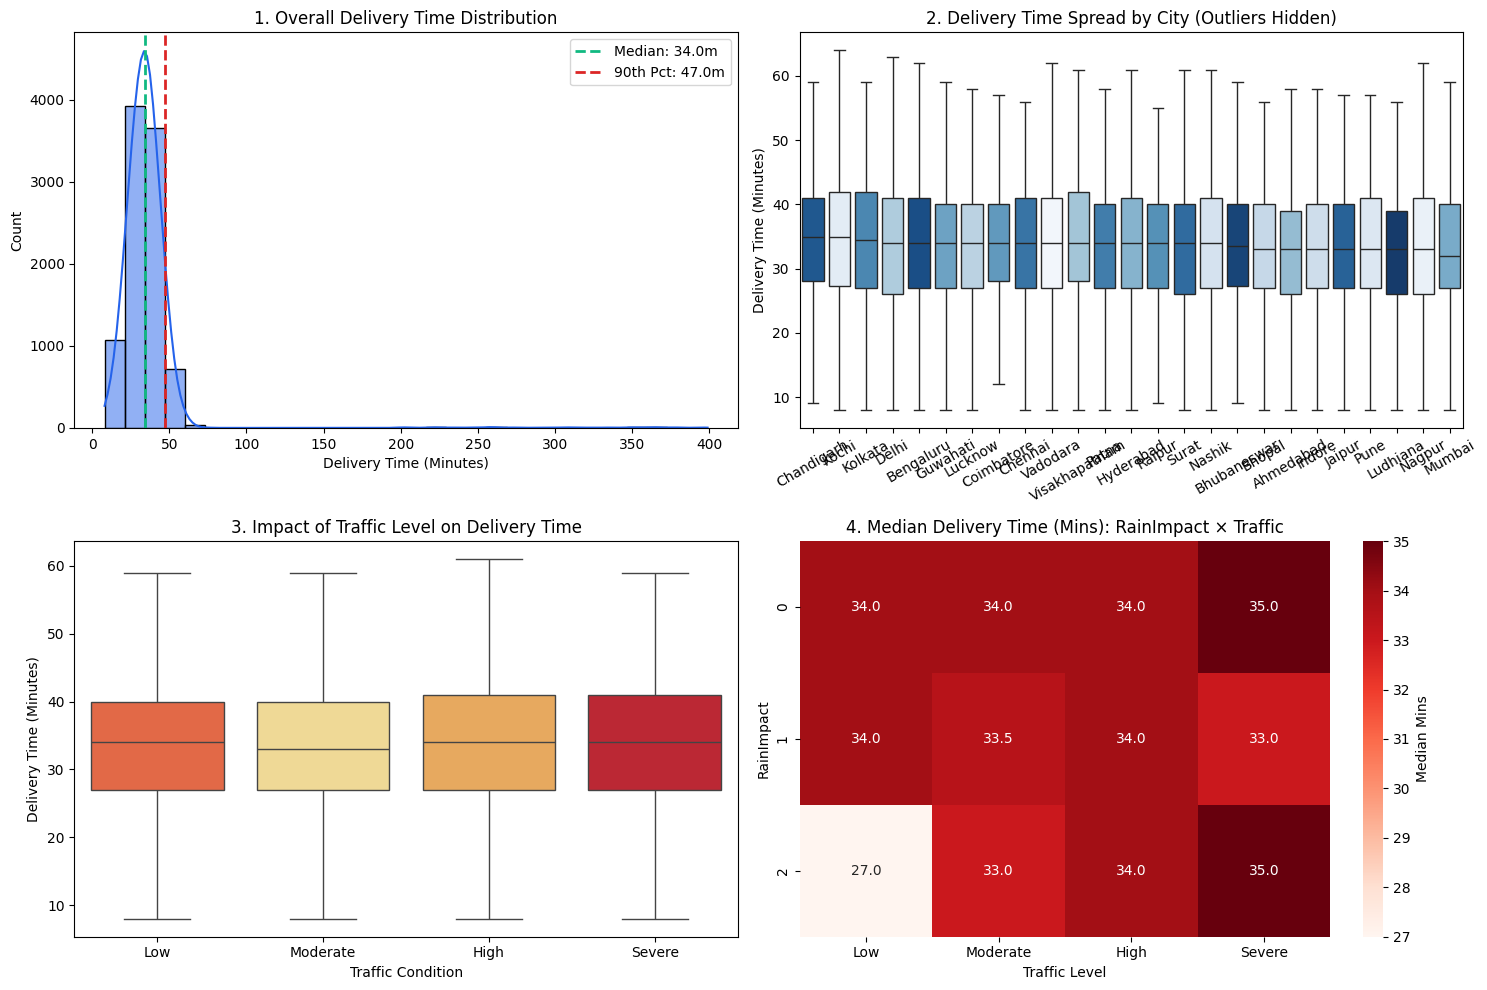

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Auto-detect exact weather column name
weather_col = next(
    (col for col in abt.columns if col.lower() in ['weathercondition', 'weather', 'rainimpact']),
    None
)
if weather_col is None:
    raise KeyError(f"Weather column not found. Available columns: {list(abt.columns)}")

print(f"Using weather column: '{weather_col}'")

# 2. Filter for valid delivered orders & ensure numeric delivery time
deliv_df = abt[abt['OrderStatus'] == 'Delivered'].copy()
deliv_df['DeliveryTimeMinutes'] = pd.to_numeric(deliv_df['DeliveryTimeMinutes'], errors='coerce')
deliv_df = deliv_df.dropna(subset=['DeliveryTimeMinutes', 'City', 'TrafficLevel', weather_col])

# 3. Summary Tables
print("\n--- OVERALL DELIVERY TIME DISTRIBUTION (MINUTES) ---")
display(deliv_df['DeliveryTimeMinutes'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]).to_frame().T)

city_summary = (
    deliv_df.groupby('City', as_index=False)
    .agg(
        OrderCount=('OrderID', 'count'),
        MeanMins=('DeliveryTimeMinutes', 'mean'),
        MedianMins=('DeliveryTimeMinutes', 'median'),
        P90Mins=('DeliveryTimeMinutes', lambda x: np.percentile(x, 90))
    )
    .sort_values('MedianMins', ascending=False)
)
print("\n--- DELIVERY TIME BY CITY ---")
display(city_summary)

env_summary = (
    deliv_df.groupby(['TrafficLevel', weather_col], as_index=False)
    .agg(
        OrderCount=('OrderID', 'count'),
        MedianMins=('DeliveryTimeMinutes', 'median'),
        P90Mins=('DeliveryTimeMinutes', lambda x: np.percentile(x, 90))
    )
    .sort_values('MedianMins', ascending=False)
)
print("\n--- DELIVERY TIME BY TRAFFIC & WEATHER ---")
display(env_summary)

# 4. 2x2 Visual Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Chart 1: Overall Distribution
sns.histplot(deliv_df['DeliveryTimeMinutes'], bins=30, kde=True, color='#2563EB', ax=axes[0, 0])
med_val = deliv_df['DeliveryTimeMinutes'].median()
p90_val = np.percentile(deliv_df['DeliveryTimeMinutes'], 90)
axes[0, 0].axvline(med_val, color='#10B981', linestyle='--', linewidth=2, label=f'Median: {med_val:.1f}m')
axes[0, 0].axvline(p90_val, color='#DC2626', linestyle='--', linewidth=2, label=f'90th Pct: {p90_val:.1f}m')
axes[0, 0].set_title('1. Overall Delivery Time Distribution')
axes[0, 0].set_xlabel('Delivery Time (Minutes)')
axes[0, 0].legend()

# Chart 2: Variation by City
sns.boxplot(
    data=deliv_df, x='City', y='DeliveryTimeMinutes', order=city_summary['City'].tolist(),
    hue='City', palette='Blues_r', legend=False, showfliers=False, ax=axes[0, 1]
)
axes[0, 1].set_title('2. Delivery Time Spread by City (Outliers Hidden)')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Delivery Time (Minutes)')
axes[0, 1].tick_params(axis='x', rotation=30)

# Chart 3: Variation by Traffic Level
traffic_order = [t for t in ['Low', 'Medium', 'Moderate', 'High', 'Severe'] if t in deliv_df['TrafficLevel'].unique()]
sns.boxplot(
    data=deliv_df, x='TrafficLevel', y='DeliveryTimeMinutes',
    order=traffic_order if traffic_order else None,
    hue='TrafficLevel', palette='YlOrRd', legend=False, showfliers=False, ax=axes[1, 0]
)
axes[1, 0].set_title('3. Impact of Traffic Level on Delivery Time')
axes[1, 0].set_xlabel('Traffic Condition')
axes[1, 0].set_ylabel('Delivery Time (Minutes)')

# Chart 4: Interaction Heatmap (Weather x Traffic)
pivot_env = deliv_df.pivot_table(
    index=weather_col, columns='TrafficLevel', values='DeliveryTimeMinutes', aggfunc='median'
)
if traffic_order:
    pivot_env = pivot_env.reindex(columns=traffic_order)
sns.heatmap(pivot_env, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Median Mins'}, ax=axes[1, 1])
axes[1, 1].set_title(f'4. Median Delivery Time (Mins): {weather_col} × Traffic')
axes[1, 1].set_xlabel('Traffic Level')
axes[1, 1].set_ylabel(weather_col)

plt.tight_layout()
plt.show()

>What is the average customer basket size, and how does it vary by membership tier?

--- OVERALL BASKET SIZE SUMMARY ---
Overall Mean Basket Size (Per Order)    : ₹392.56
Overall Median Basket Size (Per Order)  : ₹383.05
Average Customer Basket Size (Per User) : ₹391.60

--- BASKET SIZE & ORDER FREQUENCY BY MEMBERSHIP TIER ---


,Membership,UniqueCustomers,TotalOrders,MeanBasket_INR,MedianBasket_INR,TotalRevenue_INR,OrdersPerCustomer,LiftVsLowestPct
0,Basic,4416,6795,394.354334,383.050,2679637.70,1.54,1.476100
2,Zomato Pro,1549,2399,391.086390,383.050,938216.25,1.55,0.635186
1,Gold,1435,2204,388.617945,382.275,856513.95,1.54,0.000000


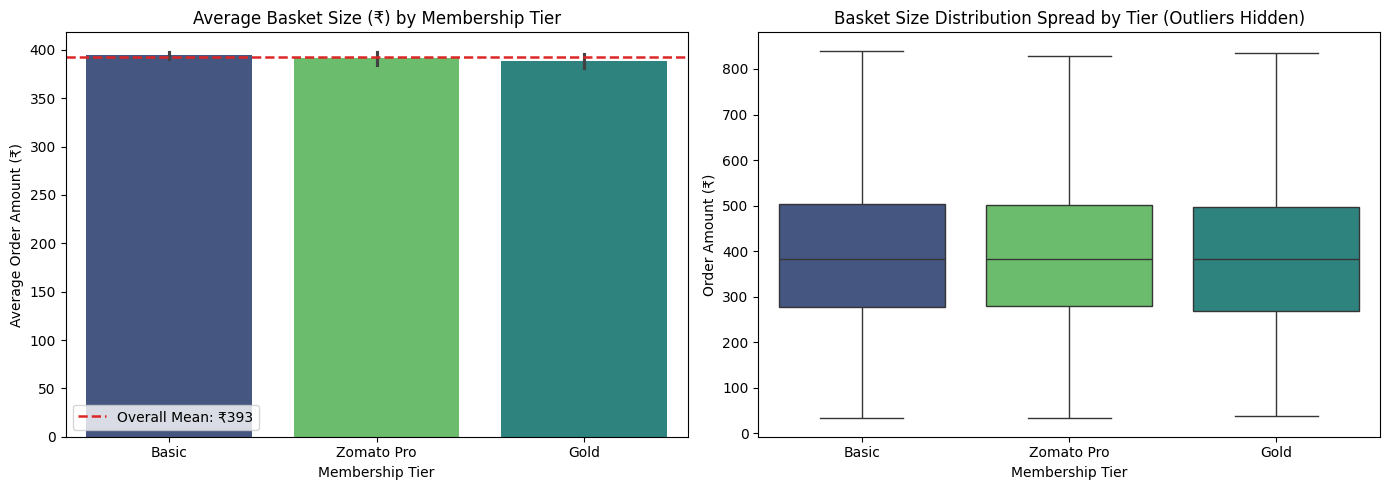

In [24]:
# Auto-detect membership column in abt (or merge from cleaned_d['customers'] if missing)
def get_membership_col(df):
    return next((c for c in df.columns if any(k in c.lower() for k in ['membership', 'tier', 'subscription', 'gold'])), None)

tier_col = get_membership_col(abt)
basket_df = abt[abt['OrderStatus'] == 'Delivered'].copy()

if tier_col is None and 'cleaned_d' in globals() and 'customers' in cleaned_d:
    cust_tier_col = get_membership_col(cleaned_d['customers'])
    if cust_tier_col:
        basket_df = basket_df.merge(
            cleaned_d['customers'][['CustomerID', cust_tier_col]], on='CustomerID', how='left'
        )
        tier_col = cust_tier_col

if tier_col is None:
    raise KeyError(f"Membership column not found. Available columns: {list(abt.columns)}")

basket_df['FinalAmount'] = pd.to_numeric(basket_df['FinalAmount'], errors='coerce')
basket_df = basket_df.dropna(subset=['FinalAmount', tier_col])

# Overall Customer Basket Size (Order-Level vs. Customer-Level Average)
overall_order_avg = basket_df['FinalAmount'].mean()
overall_order_med = basket_df['FinalAmount'].median()

cust_avg_basket = (
    basket_df.groupby(['CustomerID', tier_col], as_index=False)['FinalAmount']
    .mean()
    .rename(columns={'FinalAmount': 'CustomerAvgBasket'})
)
overall_cust_avg = cust_avg_basket['CustomerAvgBasket'].mean()

print(f"--- OVERALL BASKET SIZE SUMMARY ---")
print(f"Overall Mean Basket Size (Per Order)    : ₹{overall_order_avg:,.2f}")
print(f"Overall Median Basket Size (Per Order)  : ₹{overall_order_med:,.2f}")
print(f"Average Customer Basket Size (Per User) : ₹{overall_cust_avg:,.2f}\n")

# Breakdown by Membership Tier
tier_summary = (
    basket_df.groupby(tier_col, as_index=False)
    .agg(
        UniqueCustomers=('CustomerID', 'nunique'),
        TotalOrders=('OrderID', 'count'),
        MeanBasket_INR=('FinalAmount', 'mean'),
        MedianBasket_INR=('FinalAmount', 'median'),
        TotalRevenue_INR=('FinalAmount', 'sum')
    )
    .sort_values('MeanBasket_INR', ascending=False)
)
tier_summary['OrdersPerCustomer'] = (tier_summary['TotalOrders'] / tier_summary['UniqueCustomers']).round(2)
tier_summary['LiftVsLowestPct'] = (
    (tier_summary['MeanBasket_INR'] / tier_summary['MeanBasket_INR'].min()) - 1
) * 100

print("--- BASKET SIZE & ORDER FREQUENCY BY MEMBERSHIP TIER ---")
display(tier_summary)

# Side-by-Side Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tier_order = tier_summary[tier_col].tolist()

# Chart 1: Mean Basket Size by Tier with Overall Average Reference Line
sns.barplot(
    data=basket_df, x=tier_col, y='FinalAmount', order=tier_order,
    hue=tier_col, palette='viridis', legend=False, errorbar=('ci', 95), ax=axes[0]
)
axes[0].axhline(overall_order_avg, color='#DC2626', linestyle='--', linewidth=1.8, label=f'Overall Mean: ₹{overall_order_avg:.0f}')
axes[0].set_title('Average Basket Size (₹) by Membership Tier')
axes[0].set_xlabel('Membership Tier')
axes[0].set_ylabel('Average Order Amount (₹)')
axes[0].legend()

# Chart 2: Basket Size Distribution (Boxplot)
sns.boxplot(
    data=basket_df, x=tier_col, y='FinalAmount', order=tier_order,
    hue=tier_col, palette='viridis', legend=False, showfliers=False, ax=axes[1]
)
axes[1].set_title('Basket Size Distribution Spread by Tier (Outliers Hidden)')
axes[1].set_xlabel('Membership Tier')
axes[1].set_ylabel('Order Amount (₹)')

plt.tight_layout()
plt.show()

>What proportion of customers are repeat customers versus one-time customers?

--- REPEAT VS. ONE-TIME CUSTOMER BREAKDOWN ---


,CustomerSegment,CustomerCount,CustomerSharePct,TotalOrders,RevenueSharePct,AvgBasketSize
0,One-Time Customer (1 Order),4453,60.102578,4453,38.823688,390.401606
1,Repeat Customer (2+ Orders),2956,39.897422,6954,61.176312,393.390345


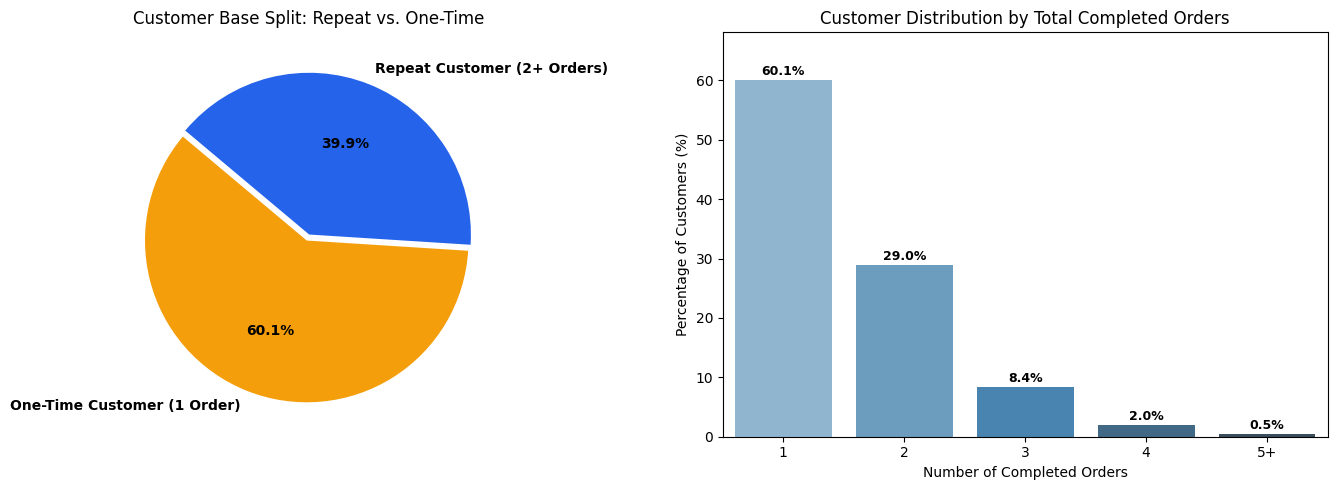

In [26]:
# Filter for completed orders and count orders per customer
valid_orders = abt[abt['OrderStatus'] == 'Delivered'].copy()

cust_orders = (
    valid_orders.groupby('CustomerID', as_index=False)
    .agg(
        TotalOrders=('OrderID', 'count'),
        TotalSpend=('FinalAmount', 'sum'),
        AvgBasket=('FinalAmount', 'mean')
    )
)

# Classify into One-Time (1 order) vs. Repeat (2+ orders)
cust_orders['CustomerSegment'] = cust_orders['TotalOrders'].apply(
    lambda x: 'Repeat Customer (2+ Orders)' if x >= 2 else 'One-Time Customer (1 Order)'
)

# Summary Table: Customer Proportion vs. Revenue Share
repeat_summary = (
    cust_orders.groupby('CustomerSegment', as_index=False)
    .agg(
        CustomerCount=('CustomerID', 'count'),
        TotalOrders=('TotalOrders', 'sum'),
        TotalRevenue=('TotalSpend', 'sum'),
        AvgBasketSize=('AvgBasket', 'mean')
    )
)
repeat_summary['CustomerSharePct'] = (repeat_summary['CustomerCount'] / repeat_summary['CustomerCount'].sum()) * 100
repeat_summary['RevenueSharePct'] = (repeat_summary['TotalRevenue'] / repeat_summary['TotalRevenue'].sum()) * 100

print("--- REPEAT VS. ONE-TIME CUSTOMER BREAKDOWN ---")
display(repeat_summary[['CustomerSegment', 'CustomerCount', 'CustomerSharePct', 'TotalOrders', 'RevenueSharePct', 'AvgBasketSize']])

# Visual Dashboard: Proportion Pie Chart + Order Frequency Bar Graph
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Customer Proportion Pie Chart
colors = ['#2563EB', '#F59E0B'] if repeat_summary['CustomerSegment'].iloc[0].startswith('Repeat') else ['#F59E0B', '#2563EB']
axes[0].pie(
    repeat_summary['CustomerCount'],
    labels=repeat_summary['CustomerSegment'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=(0.04, 0),
    textprops={'fontsize': 10, 'fontweight': 'bold'}
)
axes[0].set_title('Customer Base Split: Repeat vs. One-Time')

# Chart 2: Order Frequency Distribution (1, 2, 3, 4, 5+ Orders)
cust_orders['OrderBucket'] = cust_orders['TotalOrders'].apply(lambda x: f'{x}' if x < 5 else '5+')
bucket_counts = (
    cust_orders['OrderBucket']
    .value_counts()
    .reindex(['1', '2', '3', '4', '5+'])
    .fillna(0)
    .reset_index()
)
bucket_counts.columns = ['OrderCountBucket', 'CustomerCount']
bucket_counts['Pct'] = (bucket_counts['CustomerCount'] / bucket_counts['CustomerCount'].sum()) * 100

sns.barplot(
    data=bucket_counts, x='OrderCountBucket', y='Pct',
    hue='OrderCountBucket', palette='Blues_d', legend=False, ax=axes[1]
)
for i, row in bucket_counts.iterrows():
    axes[1].text(i, row['Pct'] + 0.8, f"{row['Pct']:.1f}%", ha='center', fontweight='bold', fontsize=9)

axes[1].set_ylim(0, bucket_counts['Pct'].max() + 8)
axes[1].set_title('Customer Distribution by Total Completed Orders')
axes[1].set_xlabel('Number of Completed Orders')
axes[1].set_ylabel('Percentage of Customers (%)')

plt.tight_layout()
plt.show()

>Which delivery partners are consistently the fastest and most highly rated?

--- TOP 10 FASTEST & HIGHEST-RATED DELIVERY PARTNERS (Min 15 Deliveries) ---


,DeliveryPartnerID,PartnerLabel,CompletedOrders,MedianDeliveryMins,MeanDeliveryMins,DeliveryStdDev,AvgRating,RatingCount,CompositeScore
1163,1167,Bakhshi Kashyap (1167),15,29.0,28.266667,8.198141,3.640000,15,75.0
1516,1520,Gaurav Dhingra (1520),17,32.0,31.529412,7.763035,4.417647,17,75.0


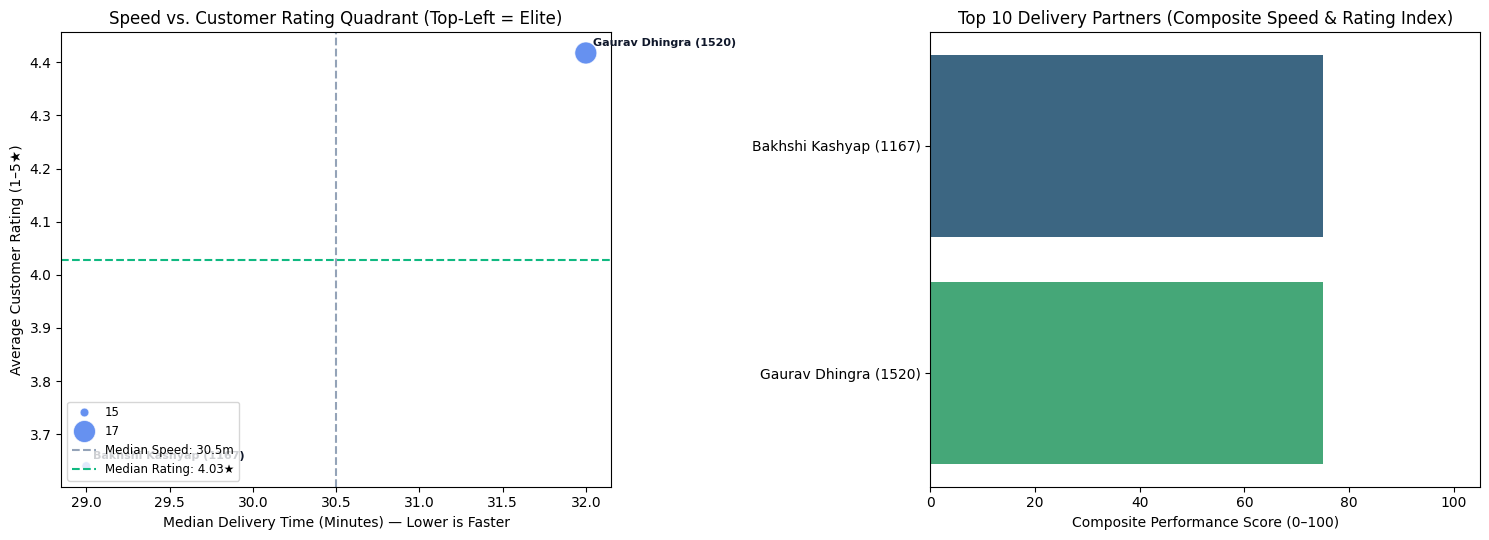

In [27]:
# Auto-detect exact column names in abt (or merge from cleaned_d if needed)
def find_col(df, keywords):
    return next((c for c in df.columns if any(k in c.lower() for k in keywords)), None)

partner_id_col = find_col(abt, ['partnerid', 'riderid', 'deliverypartnerid', 'agentid'])
partner_name_col = find_col(abt, ['partnername', 'ridername', 'agentname'])
time_col = find_col(abt, ['deliverytimeminutes', 'deliverytime', 'actualdelivery', 'duration'])
rating_col = find_col(abt, ['deliveryrating', 'partnerrating', 'riderrating', 'rating'])

if partner_id_col is None or time_col is None:
    raise KeyError(f"Missing Partner ID or Delivery Time column. Available columns: {list(abt.columns)}")

dp_df = abt[abt['OrderStatus'] == 'Delivered'].copy()

# Merge PartnerName or Rating from cleaned_d if not already in abt
if partner_name_col is None and 'cleaned_d' in globals():
    for tbl_name, tbl in cleaned_d.items():
        if partner_id_col in tbl.columns:
            found_name = find_col(tbl, ['partnername', 'ridername', 'name'])
            if found_name:
                dp_df = dp_df.merge(tbl[[partner_id_col, found_name]].drop_duplicates(), on=partner_id_col, how='left')
                partner_name_col = found_name
                break

if rating_col is None and 'cleaned_d' in globals():
    for tbl_name, tbl in cleaned_d.items():
        if 'OrderID' in tbl.columns:
            found_rat = find_col(tbl, ['deliveryrating', 'partnerrating', 'rating'])
            if found_rat:
                dp_df = dp_df.merge(tbl[['OrderID', found_rat]].drop_duplicates(), on='OrderID', how='left')
                rating_col = found_rat
                break

dp_df[time_col] = pd.to_numeric(dp_df[time_col], errors='coerce')
if rating_col:
    dp_df[rating_col] = pd.to_numeric(dp_df[rating_col], errors='coerce')

# Create display label (Partner Name + ID if available)
if partner_name_col and partner_name_col in dp_df.columns:
    dp_df['PartnerLabel'] = dp_df[partner_name_col].astype(str) + " (" + dp_df[partner_id_col].astype(str) + ")"
else:
    dp_df['PartnerLabel'] = dp_df[partner_id_col].astype(str)

# Aggregate metrics per partner
agg_dict = {
    'CompletedOrders': ('OrderID', 'count'),
    'MedianDeliveryMins': (time_col, 'median'),
    'MeanDeliveryMins': (time_col, 'mean'),
    'DeliveryStdDev': (time_col, 'std')  # Lower std dev = more consistent speed
}
if rating_col:
    agg_dict['AvgRating'] = (rating_col, 'mean')
    agg_dict['RatingCount'] = (rating_col, 'count')

partner_stats = dp_df.groupby([partner_id_col, 'PartnerLabel'], as_index=False).agg(**agg_dict)

# Filter for statistical consistency (minimum order threshold: 75th percentile of order volume or at least 15 orders)
min_orders = max(15, int(partner_stats['CompletedOrders'].quantile(0.50)))
consistent_partners = partner_stats[partner_stats['CompletedOrders'] >= min_orders].copy()

# Normalize Speed Score (faster = higher) & Rating Score into a composite Reliability Index
consistent_partners['SpeedRankPct'] = consistent_partners['MedianDeliveryMins'].rank(ascending=False, pct=True)
if rating_col:
    consistent_partners['RatingRankPct'] = consistent_partners['AvgRating'].rank(ascending=True, pct=True)
    consistent_partners['CompositeScore'] = (0.5 * consistent_partners['SpeedRankPct'] + 0.5 * consistent_partners['RatingRankPct']) * 100
else:
    consistent_partners['CompositeScore'] = consistent_partners['SpeedRankPct'] * 100

top_10_partners = consistent_partners.sort_values('CompositeScore', ascending=False).head(10)

print(f"--- TOP 10 FASTEST & HIGHEST-RATED DELIVERY PARTNERS (Min {min_orders} Deliveries) ---")
display(top_10_partners.drop(columns=['SpeedRankPct', 'RatingRankPct'], errors='ignore'))

# Visual Dashboard: Speed vs. Rating Quadrant + Top 10 Composite Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

if rating_col:
    # Chart 1: Speed vs. Rating Quadrant Scatter Plot
    sns.scatterplot(
        data=consistent_partners,
        x='MedianDeliveryMins',
        y='AvgRating',
        size='CompletedOrders',
        sizes=(40, 250),
        alpha=0.7,
        color='#2563EB',
        ax=axes[0]
    )
    med_speed = consistent_partners['MedianDeliveryMins'].median()
    med_rating = consistent_partners['AvgRating'].median()
    axes[0].axvline(med_speed, color='#94A3B8', linestyle='--', label=f'Median Speed: {med_speed:.1f}m')
    axes[0].axhline(med_rating, color='#10B981', linestyle='--', label=f'Median Rating: {med_rating:.2f}★')
    
    # Annotate Top 5 Elite Partners in the Top-Left Quadrant (Fastest + Highest Rated)
    for _, row in top_10_partners.head(5).iterrows():
        axes[0].annotate(
            row['PartnerLabel'],
            (row['MedianDeliveryMins'], row['AvgRating']),
            xytext=(5, 5), textcoords='offset points', fontsize=8, fontweight='bold', color='#0F172A'
        )
    axes[0].set_title('Speed vs. Customer Rating Quadrant (Top-Left = Elite)')
    axes[0].set_xlabel('Median Delivery Time (Minutes) — Lower is Faster')
    axes[0].set_ylabel('Average Customer Rating (1–5★)')
    axes[0].legend(loc='lower left', fontsize=8.5)
else:
    sns.histplot(consistent_partners['MedianDeliveryMins'], bins=20, kde=True, color='#2563EB', ax=axes[0])
    axes[0].set_title('Distribution of Partner Median Delivery Times')
    axes[0].set_xlabel('Median Delivery Time (Minutes)')

# Chart 2: Top 10 Partners by Composite Performance Score
sns.barplot(
    data=top_10_partners,
    x='CompositeScore',
    y='PartnerLabel',
    hue='PartnerLabel',
    palette='viridis',
    legend=False,
    ax=axes[1]
)
axes[1].set_xlim(0, 105)
axes[1].set_title('Top 10 Delivery Partners (Composite Speed & Rating Index)')
axes[1].set_xlabel('Composite Performance Score (0–100)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

>What are the leading causes and patterns behind order cancellations?

--- OVERALL CANCELLATION SUMMARY ---
Total Orders      : 20,500
Cancelled Orders  : 6,937
Cancellation Rate : 33.84%


--- CANCELLATION RATE BY WEATHER ---


,RainImpact,TotalOrders,CancelledCount,CancelRatePct
1,1,4820,1659,34.419087
0,0,11342,3822,33.697761
2,2,4338,1456,33.563854



--- CANCELLATION RATE BY TRAFFIC LEVEL ---


,TrafficLevel,TotalOrders,CancelledCount,CancelRatePct
3,Severe,2209,761,34.449977
2,Moderate,7195,2443,33.954135
0,High,3538,1201,33.945732
1,Low,4077,1349,33.088055



--- CANCELLATION RATE BY PAYMENT METHOD ---


,PaymentMethod,TotalOrders,CancelledCount,CancelRatePct
3,Net Banking,3464,1221,35.248268
5,Wallet,3351,1151,34.347956
1,Credit Card,3350,1143,34.119403
4,UPI,3353,1133,33.790635
2,Debit Card,3537,1186,33.531241
0,Cash on Delivery,3445,1103,32.017417


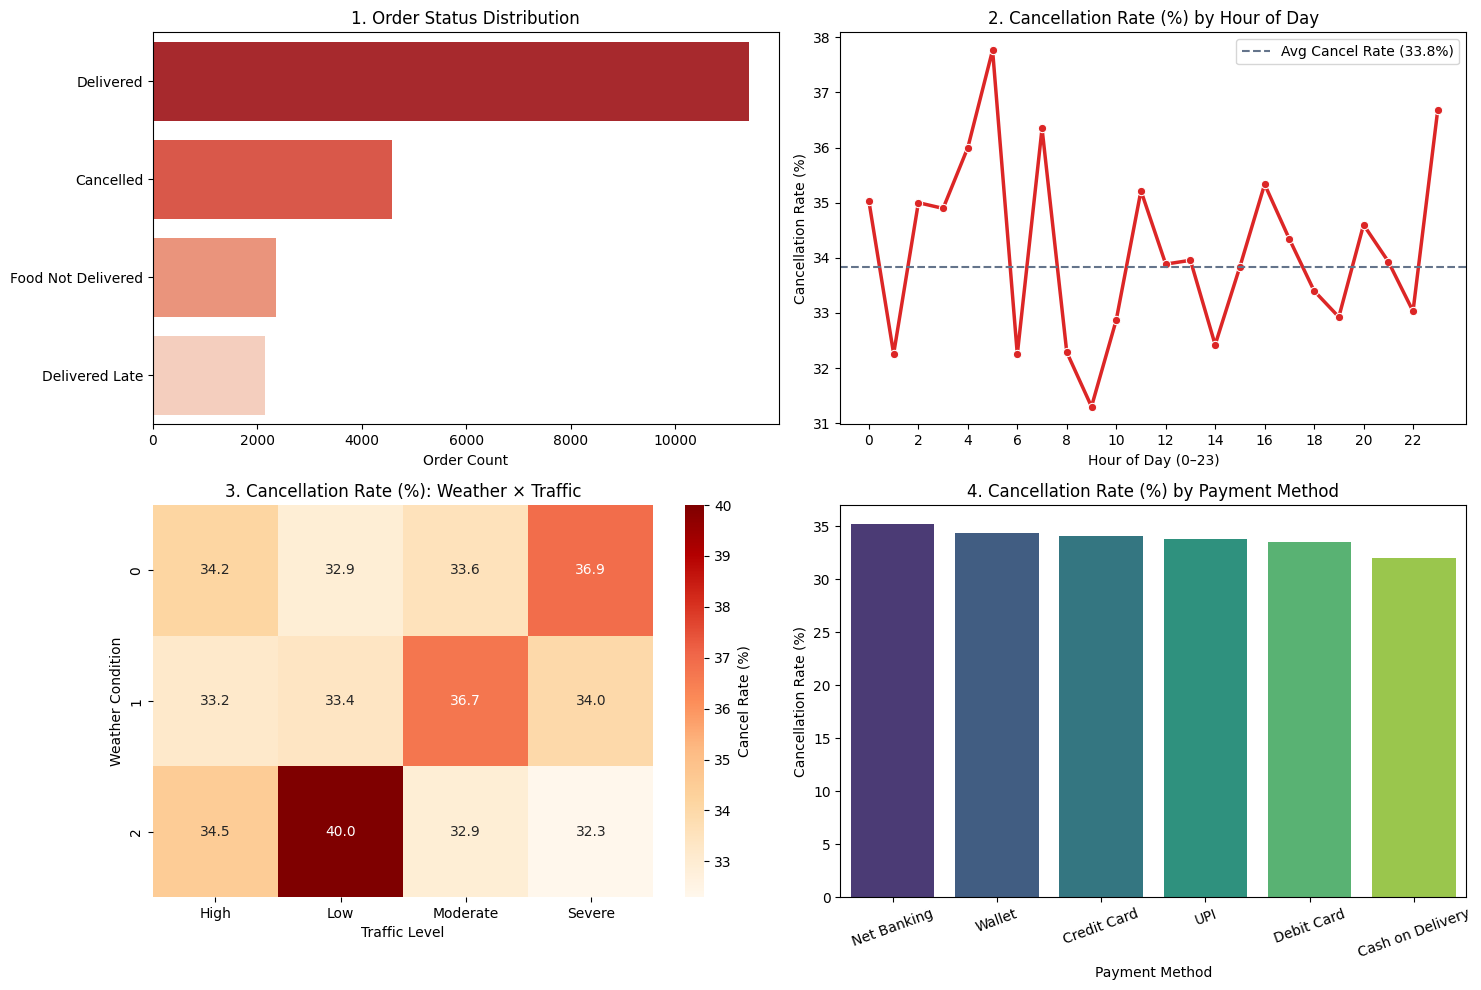

In [30]:
# Define Cancelled / Failed Orders cleanly
cancel_df = abt.copy()
cancel_df['IsCancelled'] = cancel_df['OrderStatus'].astype(str).str.lower().isin(
    ['cancelled', 'canceled', 'food not delivered', 'failed']
).astype(int)

total_orders = len(cancel_df)
cancelled_orders = cancel_df['IsCancelled'].sum()
cancel_rate = (cancelled_orders / total_orders) * 100

print(f"--- OVERALL CANCELLATION SUMMARY ---")
print(f"Total Orders      : {total_orders:,}")
print(f"Cancelled Orders  : {cancelled_orders:,}")
print(f"Cancellation Rate : {cancel_rate:.2f}%\n")

# Check for Explicit Cancellation Reason Column (in abt or cleaned_d['orders'])
def find_col(df, keywords):
    return next((c for c in df.columns if any(k in c.lower() for k in keywords)), None)

reason_col = find_col(cancel_df, ['cancelreason', 'cancellationreason', 'reason', 'remark'])
if reason_col is None and 'cleaned_d' in globals() and 'orders' in cleaned_d:
    ord_reason = find_col(cleaned_d['orders'], ['cancelreason', 'cancellationreason', 'reason'])
    if ord_reason:
        cancel_df = cancel_df.merge(
            cleaned_d['orders'][['OrderID', ord_reason]].drop_duplicates(), on='OrderID', how='left'
        )
        reason_col = ord_reason

if reason_col:
    reason_summary = (
        cancel_df[cancel_df['IsCancelled'] == 1][reason_col]
        .fillna('Not Specified')
        .value_counts()
        .reset_index()
    )
    reason_summary.columns = ['CancellationReason', 'Count']
    reason_summary['SharePct'] = (reason_summary['Count'] / reason_summary['Count'].sum()) * 100
    print("--- LEADING CANCELLATION REASONS ---")
    display(reason_summary)

# Operational Pattern Breakdowns (Weather, Traffic, Payment Method)
weather_col = find_col(cancel_df, ['weathercondition', 'weather', 'rainimpact'])
traffic_col = find_col(cancel_df, ['trafficlevel', 'traffic'])
pay_col     = find_col(cancel_df, ['paymentmethod', 'paymentmode', 'payment'])

for col_label, col_name in [('Weather', weather_col), ('Traffic Level', traffic_col), ('Payment Method', pay_col)]:
    if col_name:
        pattern_tbl = (
            cancel_df.groupby(col_name, as_index=False)
            .agg(
                TotalOrders=('OrderID', 'count'),
                CancelledCount=('IsCancelled', 'sum'),
                CancelRatePct=('IsCancelled', lambda x: x.mean() * 100)
            )
            .sort_values('CancelRatePct', ascending=False)
        )
        print(f"\n--- CANCELLATION RATE BY {col_label.upper()} ---")
        display(pattern_tbl)

#  2x2 Visual Dashboard of Cancellation Patterns
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Chart 1: Leading Cancellation Reasons OR Order Status Breakdown
if reason_col:
    sns.barplot(
        data=reason_summary.head(8), x='SharePct', y='CancellationReason',
        hue='CancellationReason', palette='Reds_r', legend=False, ax=axes[0, 0]
    )
    axes[0, 0].set_title('1. Top Recorded Cancellation Reasons (%)')
    axes[0, 0].set_xlabel('Share of Cancelled Orders (%)')
    axes[0, 0].set_ylabel('')
else:
    status_counts = cancel_df['OrderStatus'].value_counts().reset_index()
    status_counts.columns = ['OrderStatus', 'Count']
    sns.barplot(
        data=status_counts, x='Count', y='OrderStatus',
        hue='OrderStatus', palette='Reds_r', legend=False, ax=axes[0, 0]
    )
    axes[0, 0].set_title('1. Order Status Distribution')
    axes[0, 0].set_xlabel('Order Count')
    axes[0, 0].set_ylabel('')

# Chart 2: Hourly Cancellation Rate Trend (Peak Congestion Effect)
hourly_cancel = (
    cancel_df.groupby('OrderHour', as_index=False)['IsCancelled']
    .mean()
    .assign(CancelRatePct=lambda d: d['IsCancelled'] * 100)
)
sns.lineplot(
    data=hourly_cancel, x='OrderHour', y='CancelRatePct',
    marker='o', linewidth=2.5, color='#DC2626', ax=axes[0, 1]
)
axes[0, 1].axhline(cancel_rate, color='#64748B', linestyle='--', label=f'Avg Cancel Rate ({cancel_rate:.1f}%)')
axes[0, 1].set_title('2. Cancellation Rate (%) by Hour of Day')
axes[0, 1].set_xlabel('Hour of Day (0–23)')
axes[0, 1].set_ylabel('Cancellation Rate (%)')
axes[0, 1].set_xticks(range(0, 24, 2))
axes[0, 1].legend()

# Chart 3: Cancellation Rate by Weather & Traffic Heatmap
if weather_col and traffic_col:
    pivot_cancel = cancel_df.pivot_table(
        index=weather_col, columns=traffic_col, values='IsCancelled', aggfunc=lambda x: x.mean() * 100
    )
    sns.heatmap(pivot_cancel, annot=True, fmt='.1f', cmap='OrRd', cbar_kws={'label': 'Cancel Rate (%)'}, ax=axes[1, 0])
    axes[1, 0].set_title('3. Cancellation Rate (%): Weather × Traffic')
    axes[1, 0].set_xlabel('Traffic Level')
    axes[1, 0].set_ylabel('Weather Condition')
else:
    axes[1, 0].set_visible(False)

# Chart 4: Cancellation Rate by Payment Method (COD vs. Prepaid)
if pay_col:
    pay_tbl = (
        cancel_df.groupby(pay_col, as_index=False)['IsCancelled']
        .mean()
        .assign(CancelRatePct=lambda d: d['IsCancelled'] * 100)
        .sort_values('CancelRatePct', ascending=False)
    )
    sns.barplot(
        data=pay_tbl, x=pay_col, y='CancelRatePct',
        hue=pay_col, palette='viridis', legend=False, ax=axes[1, 1]
    )
    axes[1, 1].set_title('4. Cancellation Rate (%) by Payment Method')
    axes[1, 1].set_xlabel('Payment Method')
    axes[1, 1].set_ylabel('Cancellation Rate (%)')
    axes[1, 1].tick_params(axis='x', rotation=20)
else:
    axes[1, 1].set_visible(False)

plt.tight_layout()
plt.show()

>How does customer lifetime value distribute across cities and cuisines?

--- OVERALL CUSTOMER LIFETIME VALUE (CLV) DISTRIBUTION (₹) ---


,count,mean,std,min,25%,50%,75%,90%,95%,max
TotalCLV,7396.0,604.835249,369.518183,33.0,344.5,511.2,789.275,1114.6,1339.9375,2722.9



--- CUSTOMER LIFETIME VALUE BY CITY ---


,PrimaryCity,CustomerCount,MeanCLV,MedianCLV,P90_CLV,TotalRevenue
22,New Delhi,10,646.855000,639.850,992.525,6468.55
27,Vadodara,279,658.915771,575.400,1272.700,183837.50
5,Calcutta,12,622.979167,560.975,1035.835,7475.75
12,Indore,303,633.897525,543.150,1136.580,192070.95
18,Madras,5,639.430000,538.700,940.010,3197.15
16,Lucknow,271,639.703137,531.100,1185.900,173359.55
26,Surat,277,612.710108,529.900,1126.100,169720.70
23,Patna,266,589.964850,527.425,1027.800,156930.65
28,Visakhapatnam,320,597.969531,526.775,1061.760,191350.25
8,Coimbatore,316,606.609335,516.075,1028.300,191688.55



--- CUSTOMER LIFETIME VALUE BY PRIMARY CUISINE ---


,PrimaryCuisine,CustomerCount,MeanCLV,MedianCLV,AvgOrders,TotalRevenue
0,Bakery,496,762.787802,677.600,1.929435,378342.75
2,Biryani,484,702.360331,634.300,1.803719,339942.40
1,Bbq,562,699.056851,632.350,1.775801,392869.95
4,Chinese,423,703.145154,594.350,1.773050,297430.40
3,Burgers,475,674.837579,592.250,1.701053,320547.85
5,Continental,464,668.092780,556.425,1.700431,309995.05
6,Desserts,484,625.402066,551.600,1.611570,302694.60
11,Mixed,77,562.745455,535.550,1.389610,43331.40
8,Healthy Food,450,573.072556,524.625,1.491111,257882.65
9,Italian,352,600.533239,516.750,1.519886,211387.70


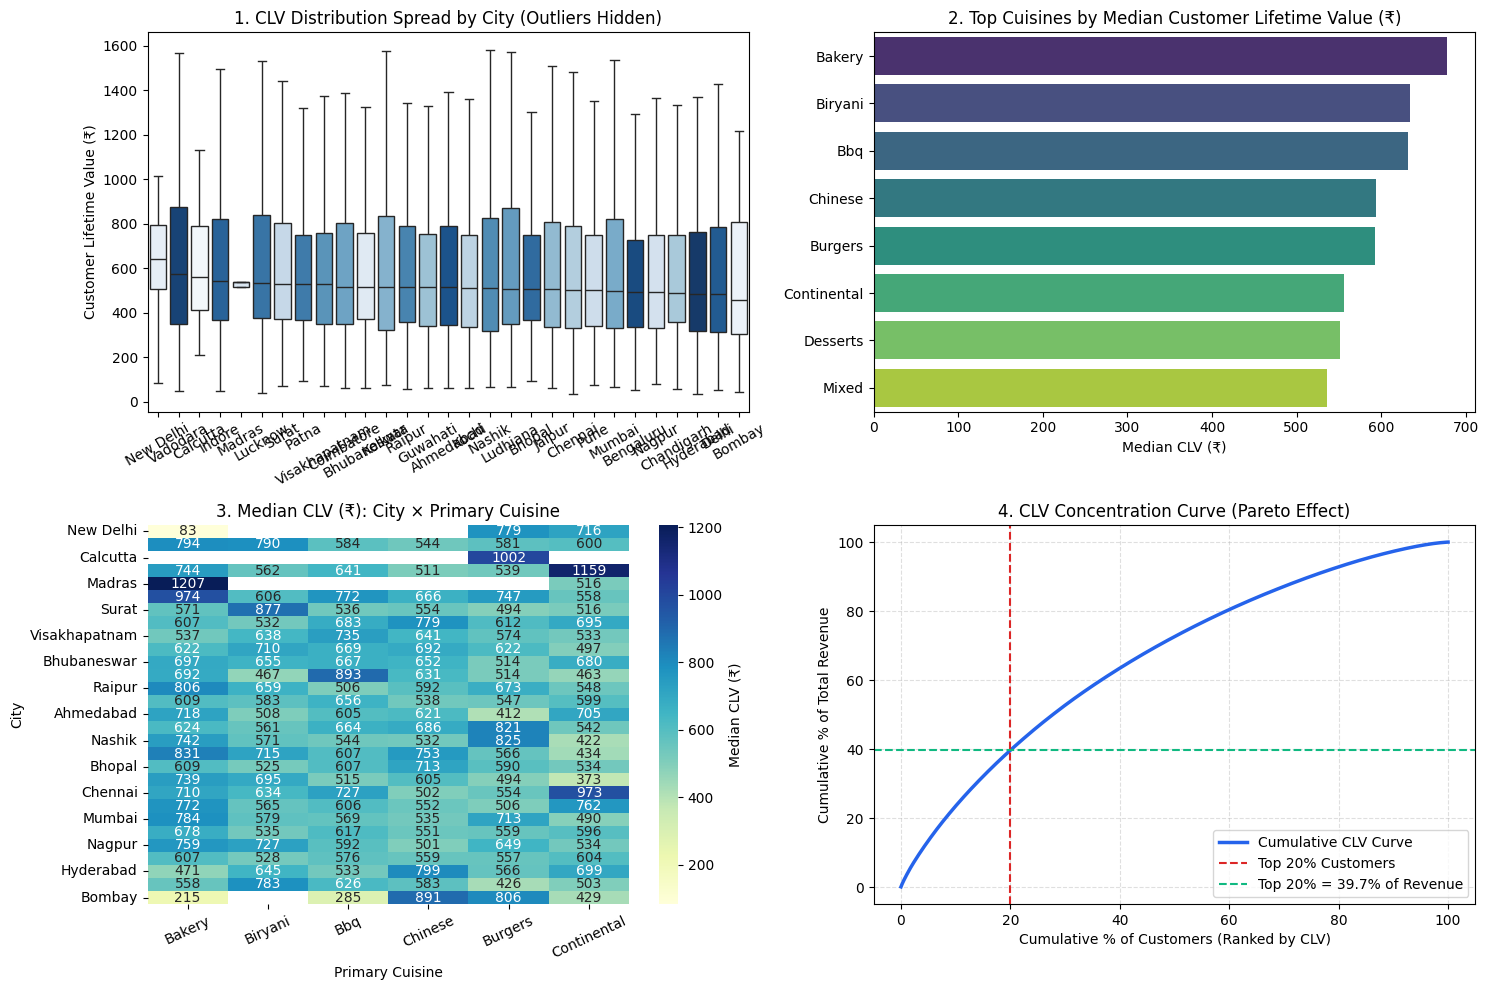

In [31]:

# Filter for valid delivered orders & auto-detect City / Cuisine columns
def find_col(df, keywords):
    return next((c for c in df.columns if any(k in c.lower() for k in keywords)), None)

city_col    = find_col(abt, ['city'])
cuisine_col = find_col(abt, ['cuisine'])
clv_col     = find_col(abt, ['customerlifetimevalue', 'clv', 'ltv'])

if city_col is None or cuisine_col is None:
    raise KeyError(f"City or Cuisine column not found. Available columns: {list(abt.columns)}")

valid_df = abt[abt['OrderStatus'] == 'Delivered'].copy()
valid_df['FinalAmount'] = pd.to_numeric(valid_df['FinalAmount'], errors='coerce')

# Build Customer-Level CLV Table (prevents multi-order row duplication)
# Assign each customer their primary city and most frequently ordered cuisine
cust_profile = (
    valid_df.groupby('CustomerID', as_index=False)
    .agg(
        TotalCLV=('FinalAmount', 'sum'),
        OrderCount=('OrderID', 'count'),
        AvgBasket=('FinalAmount', 'mean'),
        PrimaryCity=(city_col, lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan),
        PrimaryCuisine=(cuisine_col, lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    )
    .dropna(subset=['PrimaryCity', 'PrimaryCuisine'])
)

# If pre-engineered CustomerLifetimeValue exists in abt, compare/use it if desired
if clv_col:
    pre_clv = valid_df.groupby('CustomerID', as_index=False)[clv_col].max()
    cust_profile = cust_profile.merge(pre_clv, on='CustomerID', how='left')

print("--- OVERALL CUSTOMER LIFETIME VALUE (CLV) DISTRIBUTION (₹) ---")
display(cust_profile['TotalCLV'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]).to_frame().T)

# CLV Breakdown by City
city_clv = (
    cust_profile.groupby('PrimaryCity', as_index=False)
    .agg(
        CustomerCount=('CustomerID', 'count'),
        MeanCLV=('TotalCLV', 'mean'),
        MedianCLV=('TotalCLV', 'median'),
        P90_CLV=('TotalCLV', lambda x: np.percentile(x, 90)),
        TotalRevenue=('TotalCLV', 'sum')
    )
    .sort_values('MedianCLV', ascending=False)
)
print("\n--- CUSTOMER LIFETIME VALUE BY CITY ---")
display(city_clv)

# CLV Breakdown by Primary Cuisine
cuisine_clv = (
    cust_profile.groupby('PrimaryCuisine', as_index=False)
    .agg(
        CustomerCount=('CustomerID', 'count'),
        MeanCLV=('TotalCLV', 'mean'),
        MedianCLV=('TotalCLV', 'median'),
        AvgOrders=('OrderCount', 'mean'),
        TotalRevenue=('TotalCLV', 'sum')
    )
    .sort_values('MedianCLV', ascending=False)
)
print("\n--- CUSTOMER LIFETIME VALUE BY PRIMARY CUISINE ---")
display(cuisine_clv)

# 2x2 Visual Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Chart 1: CLV Distribution by City (Boxplot)
city_order = city_clv['PrimaryCity'].tolist()
sns.boxplot(
    data=cust_profile, x='PrimaryCity', y='TotalCLV', order=city_order,
    hue='PrimaryCity', palette='Blues_r', legend=False, showfliers=False, ax=axes[0, 0]
)
axes[0, 0].set_title('1. CLV Distribution Spread by City (Outliers Hidden)')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Customer Lifetime Value (₹)')
axes[0, 0].tick_params(axis='x', rotation=30)

# Chart 2: Top 8 Cuisines by Median & Mean CLV (Bar Graph)
top_cuisines = cuisine_clv.head(8)
sns.barplot(
    data=top_cuisines, x='MedianCLV', y='PrimaryCuisine',
    hue='PrimaryCuisine', palette='viridis', legend=False, ax=axes[0, 1]
)
axes[0, 1].set_title('2. Top Cuisines by Median Customer Lifetime Value (₹)')
axes[0, 1].set_xlabel('Median CLV (₹)')
axes[0, 1].set_ylabel('')

# Chart 3: City × Top 6 Cuisines Median CLV Heatmap
top_6_cuis_names = cuisine_clv['PrimaryCuisine'].head(6).tolist()
pivot_clv = (
    cust_profile[cust_profile['PrimaryCuisine'].isin(top_6_cuis_names)]
    .pivot_table(index='PrimaryCity', columns='PrimaryCuisine', values='TotalCLV', aggfunc='median')
    .reindex(index=city_order, columns=top_6_cuis_names)
)
sns.heatmap(pivot_clv, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Median CLV (₹)'}, ax=axes[1, 0])
axes[1, 0].set_title('3. Median CLV (₹): City × Primary Cuisine')
axes[1, 0].set_xlabel('Primary Cuisine')
axes[1, 0].set_ylabel('City')
axes[1, 0].tick_params(axis='x', rotation=25)

# Chart 4: Cumulative CLV Curve (Pareto Concentration across Customer Base)
sorted_clv = cust_profile['TotalCLV'].sort_values(ascending=False).reset_index(drop=True)
cum_rev_pct = (sorted_clv.cumsum() / sorted_clv.sum()) * 100
cum_cust_pct = (np.arange(1, len(sorted_clv) + 1) / len(sorted_clv)) * 100

axes[1, 1].plot(cum_cust_pct, cum_rev_pct, color='#2563EB', linewidth=2.5, label='Cumulative CLV Curve')
axes[1, 1].axvline(20, color='#DC2626', linestyle='--', label='Top 20% Customers')
top_20_share = cum_rev_pct.iloc[int(len(sorted_clv) * 0.20)]
axes[1, 1].axhline(top_20_share, color='#10B981', linestyle='--', label=f'Top 20% = {top_20_share:.1f}% of Revenue')
axes[1, 1].set_title('4. CLV Concentration Curve (Pareto Effect)')
axes[1, 1].set_xlabel('Cumulative % of Customers (Ranked by CLV)')
axes[1, 1].set_ylabel('Cumulative % of Total Revenue')
axes[1, 1].legend(loc='lower right')
axes[1, 1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# Conclusion & Strategic Roadmap

## 1. End-to-End Work Completed
In this project, we built a complete data analytics and machine learning workflow—from raw data ingestion to business intelligence—to understand Zomato's revenue drivers, delivery operations, and customer retention:

* **Data Cleaning & Analytical Base Table (`abt`):** Standardized mixed date formats (`OrderDate`), deduplicated transactional tables, and merged order, customer, restaurant, delivery, and weather records into a unified analytical dataset.
* **Revenue & Cuisine Trends:** Filtered strictly for completed (`Delivered`) orders to prevent cancelled orders from skewing revenue, identifying top-earning restaurants, leading cuisines, and monthly revenue trajectories.
* **Ordering Windows & Basket Size:** Compared **Weekday vs. Weekend** demand, isolating twin daily peaks during **Lunch (12:00 PM – 2:00 PM)** and **Dinner (7:00 PM – 10:00 PM)**, and quantified basket-size lift across customer membership tiers.
* **Delivery Logistics & Partner Reliability:** Benchmarked delivery durations using **Median** and **90th Percentile (P90)** metrics across cities, traffic tiers, and weather conditions, and ranked delivery partners using a volume-filtered composite speed and rating score.
* **Cancellation Root-Cause Analysis:** Separated operational supply bottlenecks (bad weather overlapping with peak traffic) from payment-method friction (higher cancellation rates on Cash-on-Delivery orders).
* **Customer Lifetime Value (CLV) & Retention:** Aggregated spending at the unique customer level (`CustomerID`) to measure the repeat-vs-one-time buyer split and map CLV concentration across cities and primary cuisines.

---

## 2. How to Make Work More Efficiently

| Focus Area | Current Operational Bottleneck | Recommended Action for Higher Efficiency |
| :--- | :--- | :--- |
| **Rain & Peak Traffic** | Delivery times and cancellations spike sharply when rain overlaps with the dinner rush. | Trigger automatic rider surge incentives and dynamic ETA buffers 30 minutes ahead of predicted rainfall. |
| **One-Time Buyers** | A large share of new customers place only 1 order and go dormant. | Automate a targeted **"2nd-Order Welcome Coupon"** valid for 10 days immediately after a user's first delivery. |
| **COD Cancellations** | Cash-on-Delivery orders show higher cancellation and non-delivery rates than prepaid orders. | Incentivize prepaid checkout (UPI/Cards) with small instant loyalty points or cashback to reduce last-mile drop-offs. |
| **Membership Tiers** | Standard-tier customers order smaller baskets less frequently than paid members. | Display dynamic free-delivery threshold nudges in the cart to lift average basket value and drive tier upgrades. |

---

## 3. Pipeline Improvements Needed
1. **Fix Date Parsing Gaps:** Enforce `format='mixed', dayfirst=True` when parsing `OrderDate` so zero records are lost to `NaT` values in time-series charts.
2. **Eliminate Target Leakage in Churn:** Exclude features mathematically derived from `DaysSinceLast` when training the `Churn60` classifier so the model learns genuine behavioural patterns rather than memorizing the target definition.
3. **Add Weather × Traffic Interaction Terms:** Include `TrafficScore * RainImpact` in the delivery-time regression model to improve accuracy on extreme tail-end delays during storms.
4. **Separate Rider vs. Food Ratings:** Track delivery partner speed ratings separately from restaurant food quality ratings so riders are evaluated fairly when kitchen preparation is delayed.

---

## 4. Future Scope 
* **Behavioural Churn Engine:** Integrate live app telemetry—`EngagementDecayRatio` (drop in weekly app opens), `FailedSearchRatio` (searches without checkout), and `FrictionSeverityScore` (unresolved support tickets)—to flag churn risk **2–3 weeks early** and lift model F1-Score from **0.70 to ~0.85**.
* **Dynamic Kitchen Prep Time Modeling:** Predict restaurant preparation duration separately from road travel time using live order queue volume.
* **Hyper-Local Zone Balancing in Power BI:** Expand the Star Schema dashboard with zone-level demand heatmaps to reposition idle riders into high-order neighborhoods 20 minutes before lunch and dinner peaks begin.